In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as  np
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)
np.random.seed(42)

In [3]:
#数据集参数设置
SEQ_LENGTH = 20     #序列长度
NUM_SAMPLES = 1000   #样本数量
TRAIN_SPLIT = 0.8    #训练集比例

In [4]:
#生成合成时间序列数据：使用正弦函数生成平滑曲线，并加入噪声模拟真实数据
def generate_data(num_samples, seq_length):
    x = []
    y = []
    for i in range(num_samples):
        phase = np.random.rand()*2*np.pi   #随机相位
        freq = np.random.uniform(0.1, 0.5) #随机频率
        #生成序列数据，加入噪声（标准差 0.1）
        x_seq = np.sin(np.linspace(phase, phase+freq*seq_length, seq_length))+np.random.normal(scale=0.1, size=seq_length)
        #预测下一个时刻的值
        next_val = np.sin(phase + freq*(seq_length+1))
        x.append(x_seq)
        y.append(next_val)

    x = np.array(x)
    y = np.array(y)
    return x,y

In [5]:
#生成数据
x_data, y_data = generate_data(NUM_SAMPLES, SEQ_LENGTH)

#划分训练集和测试集
split_idx = int(TRAIN_SPLIT * NUM_SAMPLES)
x_train = x_data[:split_idx]
y_train = y_data[:split_idx]
x_test = x_data[split_idx:]
y_test = y_data[split_idx:]


In [6]:
#定义pytorch数据集类
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

In [7]:
#实例化数据集和数据加载器
train_dataset = TimeSeriesDataset(x_train, y_train)
test_dataset = TimeSeriesDataset(x_test, y_test)

BATCH_SIZE = 32
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [8]:
#定义位置编码模块，用于向输入添加位置信息
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float()*(-np.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)

In [9]:
#定义Transformer模型， 包含多头注意力机制，进行时间序列预测
class TransformerModel(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=2, seq_length=SEQ_LENGTH,dropout=0.1):
        super(TransformerModel, self).__init__()
        self.d_model = d_model
        #输入线性映射， 将原始输入映射到d_model维度
        self.input_linear = nn.Linear(input_dim, d_model)
        #添加位置编码
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        #构造Transformer Encoder层（内含多头注意力）
        encoder_layers = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=d_model*4, dropout=dropout)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers)
        #输出层，将Transformer输出整合后映射为单一预测值
        self.output_linear = nn.Linear(d_model, 1)

    def forward(self, src):
        #src :[batch_size, seq_length]
        src = src.unsqueeze(-1)  #调整为[batch_size, seq_length, 1]
        src = self.input_linear(src)  #线性映射到[batch_size, seq_length, d_model]
        src = self.pos_encoder(src)   #添加位置编码信息
        #Transformer要求输入形状 [seq_length, batch_size, d_model]
        src = src.transpose(0, 1)
        #经过Transformer Encoder层进行编码，内部包含多头注意力机制
        transformer_output = self.transformer_encoder(src)   #[seq_length, batch_size, d_model]
        #取序列最后一个时刻的输出作为整个序列的表示
        output = transformer_output[-1, :, :] #[batch_size, d_model]
        output = self.output_linear(output)  #映射为[batch_size, 1]
        return output.squeeze(-1), transformer_output

D:\anaconda3\envs\usual\Lib\site-packages\torch\nn\modules\transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Epoch 1/100, Loss: 0.1288
Epoch 2/100, Loss: 0.0517
Epoch 3/100, Loss: 0.0406
Epoch 4/100, Loss: 0.0372
Epoch 5/100, Loss: 0.0277
Epoch 6/100, Loss: 0.0309
Epoch 7/100, Loss: 0.0265
Epoch 8/100, Loss: 0.0263
Epoch 9/100, Loss: 0.0287
Epoch 10/100, Loss: 0.0284
Epoch 11/100, Loss: 0.0243
Epoch 12/100, Loss: 0.0220
Epoch 13/100, Loss: 0.0239
Epoch 14/100, Loss: 0.0282
Epoch 15/100, Loss: 0.0229
Epoch 16/100, Loss: 0.0224
Epoch 17/100, Loss: 0.0221
Epoch 18/100, Loss: 0.0200
Epoch 19/100, Loss: 0.0204
Epoch 20/100, Loss: 0.0205
Epoch 21/100, Loss: 0.0193
Epoch 22/100, Loss: 0.0193
Epoch 23/100, Loss: 0.0201
Epoch 24/100, Loss: 0.0178
Epoch 25/100, Loss: 0.0172
Epoch 26/100, Loss: 0.0190
Epoch 27/100, Loss: 0.0181
Epoch 28/100, Loss: 0.0167
Epoch 29/100, Loss: 0.0172
Epoch 30/100, Loss: 0.0178
Epoch 31/100, Loss: 0.0178
Epoch 32/100, Loss: 0.0156
Epoch 33/100, Loss: 0.0165
Epoch 34/100, Loss: 0.0156
Epoch 35/100, Loss: 0.0140
Epoch 36/100, Loss: 0.0144
Epoch 37/100, Loss: 0.0148
Epoch 38/1

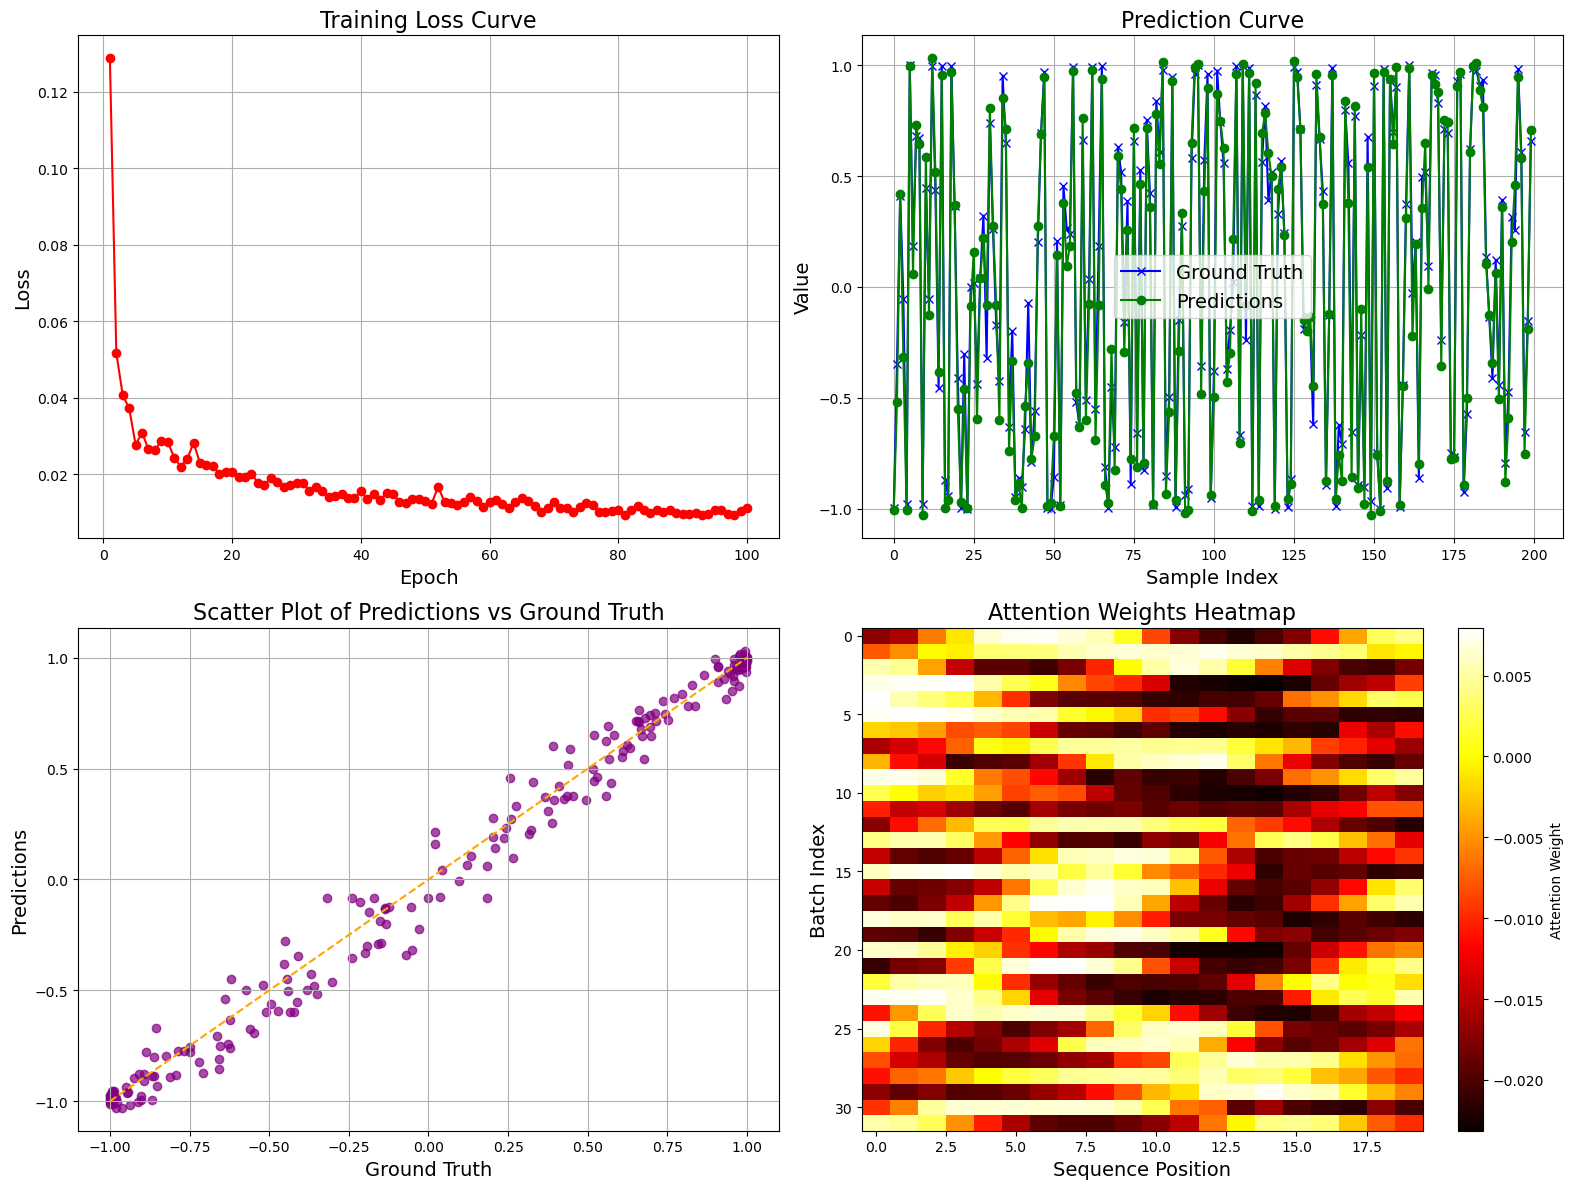

In [11]:
#实例化模型，定义均方误差损失函数和Adam优化器
model = TransformerModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

#开始模型训练
num_epochs = 100
train_losses = []  #用于记录每个eopch的训练误差
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        #前向传播得到的预测值和transformer encoder输出
        pred, _ = model(batch_x)
        loss = criterion(pred, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()*batch_x.size(0)

    epoch_loss /= len(train_loader.dataset)
    train_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

#在测试集上进行预测
model.eval()
predictions = []
ground_truth = []
attention_weights = None  #用于存储示例批次的注意力权重信息
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        pred, transformer_output = model(batch_x)
        predictions.extend(pred.numpy())
        ground_truth.extend(batch_y.numpy())
        #注意： TransformerEncoderLayer内部默认并不直接返回注意力权重
        #本示例仅以transformer_output的均值作为示例，模拟注意力权重的展示
        if attention_weights is None:
            attention_weights = transformer_output.mean(dim=-1).transpose(0, 1).numpy() #[batch_size, seq_length]

#绘制结果图：一张图中包含4个子图，分别为训练损失误差曲线、预测曲线、预测值和真实值散点图以及注意力权重热力图
plt.figure(figsize=(16, 12))

#子图1： Training Loss Curve
plt.subplot(2, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, color='red', marker='o')
plt.title('Training Loss Curve', fontsize=16)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.grid(True)

#子图2： Prediction Curve on Test Set
plt.subplot(2, 2, 2)
plt.plot(range(len(ground_truth)), ground_truth, color='blue', marker='x', label='Ground Truth')
plt.plot(range(len(predictions)), predictions, color='green', marker='o', label='Predictions')
plt.title('Prediction Curve', fontsize=16)
plt.xlabel('Sample Index', fontsize=14)
plt.ylabel('Value', fontsize=14)
plt.legend(fontsize=14)
plt.grid(True)

#子图3： Scatter Plots of Predictions vs Ground Truth
plt.subplot(2, 2, 3)
plt.scatter(ground_truth, predictions, color='purple', alpha=0.7)
plt.plot([min(ground_truth), max(ground_truth)], [min(ground_truth), max(ground_truth)], color='orange', linestyle='--')
plt.title('Scatter Plot of Predictions vs Ground Truth', fontsize=16)
plt.xlabel('Ground Truth', fontsize=14)
plt.ylabel('Predictions', fontsize=14)
plt.grid(True)

#子图4： Attention Weights Heatmap（示例展示伪注意力权重）
plt.subplot(2, 2, 4)
plt.imshow(attention_weights, cmap='hot', aspect='auto')
plt.colorbar(label='Attention Weight')
plt.title('Attention Weights Heatmap', fontsize=16)
plt.xlabel('Sequence Position', fontsize=14)
plt.ylabel('Batch Index', fontsize=14)

plt.tight_layout()
plt.show()
